In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import matplotlib.colors as mcolors

# Stats
import statsmodels.api as sm

In [2]:
from analysis import *

There are 3 real clones that have < 2 observation times.


In [3]:
# supplement_mode: determines whether to plot the figure that goes in
# the main body, or the extended version in the supplement.
supplement_mode = False

# Define mapping from scenario string to numeric r
scenario_map = {
    'full_pipeline': 'Exp. data',
    'r36_rp0.5_mimic': 'Model\n$rp=0.5$',
    'r36_rp2_mimic': 'Model\n$rp=2$',
    'r36_rp8_mimic': 'Model\n$rp=8$',
    'r36_rp25_mimic': 'Model\n$rp=25$'
}

palette = {
    'Exp. data': exp_hue,
    'Model\n$rp=0.5$': hue(0.5),
    'Model\n$rp=2$': hue(2),
    'Model\n$rp=8$': hue(8),
    'Model\n$rp=25$': hue(25),
}

if supplement_mode:
    scenario_map.update({
        'no_collapse': 'Exp. data\n(no cluster)',
        'full_pipeline_trunc': 'Exp. data\n(trunc.)'
    })

    palette.update({
        'Exp. data\n(no cluster)': no_collapse_hue,
        'Exp. data\n(trunc.)': trunc_hue
    })

    order = ['Exp. data', 'Exp. data\n(trunc.)', 'Exp. data\n(no cluster)',
         'Model\n$rp=0.5$', 'Model\n$rp=2$', 'Model\n$rp=8$', 'Model\n$rp=25$']
else:
    order = ['Exp. data', 'Model\n$rp=0.5$', 'Model\n$rp=2$', 'Model\n$rp=8$', 'Model\n$rp=25$']

df_plot = df.query('scenario.isin(@scenario_map.keys())').copy()
df_plot = df_plot.query('duplicate == 0').copy()
df_plot['scenario_label'] = df_plot['scenario'].map(scenario_map)

zero_counts = df_plot.groupby('scenario_label')['r_opt'].apply(lambda x: (x==0).mean()*100)

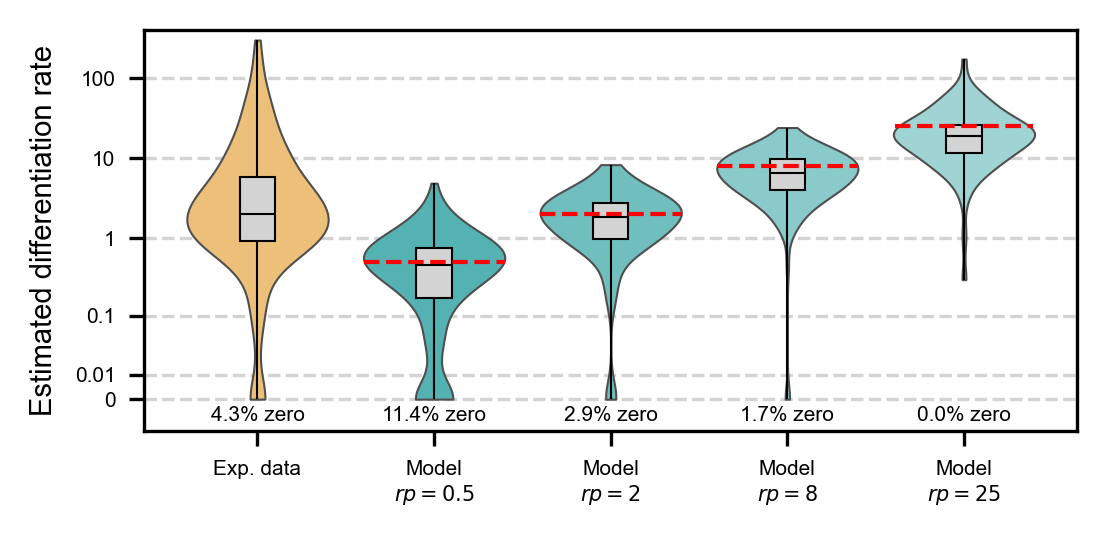

In [11]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

if supplement_mode:
    fig, ax = plt.subplots(figsize = (3.5, 1.3), dpi = 300)    
    filepath = os.path.join('images', 'violin_supplement.svg')
else:
    fig, ax = plt.subplots(figsize = (3.7, 1.8), dpi = 300)    
    filepath = os.path.join('images', 'violin.svg')

sns.violinplot(
    data=df_plot, x='scenario_label', y='symlog10_r',
    order=order,
    inner=None, cut=0, hue='scenario_label',
    density_norm='area', linewidth=0.5, palette=palette, ax=ax, legend=False
)

sns.boxplot(
    data=df_plot, x='scenario_label', y='symlog10_r',
    order=order,
    whis=np.inf, width=0.2, showcaps=False,
    boxprops={'facecolor':'lightgray', 'edgecolor':'black', 'linewidth':0.5},
    whiskerprops={'color':'black', 'linewidth':0.5},
    capprops={'color':'black', 'linewidth':0.5},
    medianprops={'color':'black', 'linewidth':0.5},
    ax=ax
)

# "True" r values in red dashed lines
for i, r in enumerate([0.5, 2, 8, 25]):
    col = i + (len(order) - 4)
    y_val = symlog10(r, linthresh=1e-2)  
    
    poly = ax.collections[col]
    verts = poly.get_paths()[0].vertices
    mask = np.isclose(verts[:,1], y_val, atol=0.05)  # tolerance around y_val
    x_coords = verts[mask,0]
    
    xmin, xmax = x_coords.min(), x_coords.max()
    ax.hlines(
        y_val, xmin, xmax, colors='red', linestyles='dashed', linewidth=1
    )

for i, key in enumerate(order):
    pct = zero_counts.get(key, 0)
    ax.text(
        i, -0.2, f"{pct:.1f}% zero",
        ha='center', va='center', fontsize=5
    )

ax.set_xlabel('')

# Set y ticks.
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
ax.set_yticks(tick_symlog)
ax.set_yticklabels([str(r) for r in tick_r])
ax.set_ylim([-0.4, 4.6])
if supplement_mode:
    ax.set_ylabel('Estimated drift strength')
else:
    ax.set_ylabel('Estimated differentiation rate')


ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis='y')
ax.set_axisbelow(True) 

plt.tight_layout()
plt.savefig(filepath, pad_inches = 0)